
# PRAKTIKUM DATA MINING

## Evaluasi Model Klasifikasi: Confusion Matrix, Accuracy, Precision, Recall, dan F1-Score

---

### IDENTITAS MAHASISWA

| Keterangan | Identitas |
|---|---|
| Nama | Ridho Dwi Putra Zendy |
| NIM | 24343106 |
| Program Studi | Informatika |

---

### DESKRIPSI PRAKTIKUM

Praktikum ini membahas evaluasi model klasifikasi menggunakan
Confusion Matrix, Accuracy, Precision, Recall, dan F1-Score.

Studi kasus yang digunakan adalah klasifikasi transaksi pembayaran
digital untuk membedakan transaksi normal dan transaksi fraud
(penipuan) menggunakan algoritma Decision Tree.

Praktikum dilakukan menggunakan bahasa pemrograman Python
dengan bantuan library NumPy, Pandas, Scikit-learn, dan Matplotlib.

### TUJUAN PRAKTIKUM

1. Mengidentifikasi True Positive (TP), True Negative (TN),
   False Positive (FP), dan False Negative (FN).
2. Menghitung Accuracy, Precision, Recall, dan F1-Score.
3. Menghasilkan prediksi klasifikasi menggunakan Decision Tree.
4. Memvisualisasikan dan menginterpretasikan Confusion Matrix.
5. Memahami evaluasi model pada data tidak seimbang.
6. Menganalisis pengaruh threshold terhadap hasil klasifikasi.

---

## 4. LANGKAH-LANGKAH PRAKTIKUM

Pelaksanaan praktikum dilakukan berdasarkan tahapan
yang terdapat dalam Modul Praktikum Data Mining.


## 4.1 Menyiapkan Dataset Sintetis

Pada tahap ini, dilakukan pembuatan dataset sintetis (data buatan) yang digunakan untuk simulasi klasifikasi transaksi pembayaran digital. Dataset terdiri dari 500 data transaksi dengan beberapa atribut, yaitu:

1. **amount**: Nominal transaksi dalam satuan simulasi.
2. **hour**: Jam ketika transaksi dilakukan, dengan rentang 0–23.
3. **new_device**: Menunjukkan apakah transaksi menggunakan perangkat baru (1 = Ya, 0 = Tidak).
4. **foreign_ip**: Menunjukkan apakah transaksi berasal dari IP luar negeri (1 = Ya, 0 = Tidak).
5. **isFraud**: Label target yang menunjukkan status transaksi (1 = Fraud, 0 = Normal).

Pembuatan dataset menggunakan NumPy dengan random seed sebesar 42 agar proses pembangkitan data dapat direproduksi sehingga hasilnya konsisten ketika kode dijalankan kembali.

Dataset ini digunakan sebagai data simulasi untuk mempelajari proses klasifikasi dan evaluasi model, bukan merupakan data transaksi sebenarnya.

In [3]:
import numpy as np
import pandas as pd

# Membuat generator angka acak dengan seed 42
rng = np.random.default_rng(42)

# Menentukan jumlah data transaksi
n = 500

# Membuat fitur-fitur transaksi
amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)

# Menghitung skor kemungkinan terjadinya fraud
score = (
    -4.5
    + 0.45 * (amount > 300)
    + 1.1 * new_device
    + 1.5 * foreign_ip
    + 0.7 * (hour < 5)
)

# Mengubah skor menjadi probabilitas
prob = 1 / (1 + np.exp(-score))

# Membuat label fraud berdasarkan probabilitas
isFraud = rng.binomial(1, prob)

# Menggabungkan seluruh fitur menjadi DataFrame
df = pd.DataFrame({
    'amount': amount.round(2),
    'hour': hour,
    'new_device': new_device,
    'foreign_ip': foreign_ip,
    'isFraud': isFraud
})

# Menampilkan lima data pertama
print("Lima Data Transaksi Pertama:")
print(df.head())

# Menampilkan distribusi kelas
print("\nDistribusi Kelas:")
print(df['isFraud'].value_counts())


Lima Data Transaksi Pertama:
   amount  hour  new_device  foreign_ip  isFraud
0  201.28     9           0           0        0
1   52.46     8           0           0        0
2  314.33    17           1           0        0
3  380.15     3           0           0        0
4   21.09     5           1           0        0

Distribusi Kelas:
isFraud
0    484
1     16
Name: count, dtype: int64


## 4.2 Membagi Data dan Melatih Model

Pada tahap ini, dataset yang telah dibuat akan dipisahkan menjadi data latih (training data) dan data uji (testing data).

Pembagian data dilakukan menggunakan fungsi `train_test_split()` dari library scikit-learn dengan ketentuan:

- Data latih sebesar 70%.
- Data uji sebesar 30%.
- `random_state=42` untuk menjaga konsistensi pembagian data.
- `stratify=y` untuk mempertahankan proporsi kelas pada data latih dan data uji.

Selanjutnya, dilakukan pembangunan model klasifikasi menggunakan algoritma Decision Tree Classifier dengan parameter `max_depth=4` dan `class_weight='balanced'`.

Model dilatih menggunakan data latih melalui fungsi `fit()`, kemudian digunakan untuk memprediksi kelas pada data uji melalui fungsi `predict()`.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# Memisahkan fitur dan label
X = df.drop(columns='isFraud')
y = df['isFraud']

# Membagi dataset menjadi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Membuat model Decision Tree
model = DecisionTreeClassifier(
    max_depth=4,
    class_weight='balanced',
    random_state=42
)

# Melatih model menggunakan data latih
model.fit(X_train, y_train)

# Melakukan prediksi pada data uji
y_pred = model.predict(X_test)

# Menampilkan jumlah data uji
print('Data uji:', len(y_test))


Data uji: 150


## 4.3 Menghitung Confusion Matrix

Pada tahap ini, dilakukan evaluasi terhadap hasil prediksi model Decision Tree dengan membandingkan label aktual (`y_test`) dan label prediksi (`y_pred`).

Evaluasi dilakukan menggunakan Confusion Matrix, yaitu sebuah tabel yang digunakan untuk mengetahui jumlah prediksi benar dan salah dari model klasifikasi.

Confusion Matrix memiliki empat komponen utama:

1. **True Positive (TP):** Transaksi fraud yang berhasil diprediksi sebagai fraud.
2. **True Negative (TN):** Transaksi normal yang berhasil diprediksi sebagai normal.
3. **False Positive (FP):** Transaksi normal yang salah diprediksi sebagai fraud.
4. **False Negative (FN):** Transaksi fraud yang salah diprediksi sebagai normal.

Pada praktikum ini, kelas positif adalah fraud (1), sedangkan kelas negatif adalah normal (0).

Dengan demikian, Confusion Matrix digunakan untuk mengetahui seberapa baik model dalam mengenali transaksi normal maupun mendeteksi transaksi fraud.

In [5]:
from sklearn.metrics import confusion_matrix

# Menghitung confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Mengambil nilai TN, FP, FN, dan TP
tn, fp, fn, tp = cm.ravel()

# Menampilkan confusion matrix
print("Confusion Matrix:")
print(cm)

# Menampilkan empat komponen confusion matrix
print(f"TP = {tp}")
print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")


Confusion Matrix:
[[113  32]
 [  3   2]]
TP = 2
TN = 113
FP = 32
FN = 3


## 4.4 Perhitungan Manual dan Verifikasi

Pada tahap ini, dilakukan perhitungan metrik evaluasi klasifikasi secara manual berdasarkan nilai TP, TN, FP, dan FN yang diperoleh dari Confusion Matrix.

Terdapat empat metrik yang digunakan, yaitu:

1. **Accuracy:** Mengukur persentase seluruh prediksi yang benar dibandingkan dengan jumlah keseluruhan data.
2. **Precision:** Mengukur ketepatan model ketika memprediksi suatu transaksi sebagai fraud.
3. **Recall:** Mengukur kemampuan model dalam menemukan seluruh transaksi fraud yang sebenarnya.
4. **F1-Score:** Mengukur keseimbangan antara precision dan recall.

Setelah perhitungan manual dilakukan, hasilnya akan dibandingkan dengan perhitungan menggunakan fungsi evaluasi dari scikit-learn.

Tujuannya adalah memastikan bahwa perhitungan manual dan hasil dari library scikit-learn memberikan nilai yang sama.

In [6]:
# Menghitung Accuracy
accuracy = (tp + tn) / (tp + tn + fp + fn)

# Menghitung Precision
precision = tp / (tp + fp) if (tp + fp) else 0

# Menghitung Recall
recall = tp / (tp + fn) if (tp + fn) else 0

# Menghitung F1-Score
f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) else 0
)

# Menampilkan hasil perhitungan manual
print("Hasil Perhitungan Manual:")
print(f"Accuracy  = {accuracy:.3f}")
print(f"Precision = {precision:.3f}")
print(f"Recall    = {recall:.3f}")
print(f"F1-Score  = {f1:.3f}")


Hasil Perhitungan Manual:
Accuracy  = 0.767
Precision = 0.059
Recall    = 0.400
F1-Score  = 0.103


In [8]:
# Mengimpor fungsi evaluasi
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Menghitung metrik menggunakan scikit-learn
accuracy_sklearn = accuracy_score(y_test, y_pred)

precision_sklearn = precision_score(
    y_test, y_pred, zero_division=0
)

recall_sklearn = recall_score(
    y_test, y_pred, zero_division=0
)

f1_sklearn = f1_score(
    y_test, y_pred, zero_division=0
)

# Menampilkan hasil verifikasi
print("Hasil Perhitungan Scikit-Learn:")
print(f"Accuracy  = {accuracy_sklearn:.3f}")
print(f"Precision = {precision_sklearn:.3f}")
print(f"Recall    = {recall_sklearn:.3f}")
print(f"F1-Score  = {f1_sklearn:.3f}")


Hasil Perhitungan Scikit-Learn:
Accuracy  = 0.767
Precision = 0.059
Recall    = 0.400
F1-Score  = 0.103


## 4.5 Visualisasi Confusion Matrix

Pada tahap ini, dilakukan visualisasi Confusion Matrix menggunakan library Matplotlib dan fitur `ConfusionMatrixDisplay` dari scikit-learn.

Visualisasi bertujuan untuk mempermudah pemahaman terhadap hasil klasifikasi model Decision Tree dengan menampilkan jumlah prediksi benar dan salah dalam bentuk grafik.

Grafik Confusion Matrix menampilkan dua kategori utama, yaitu transaksi normal dan transaksi fraud. Setiap sel menunjukkan jumlah transaksi berdasarkan perbandingan antara kelas aktual dan kelas prediksi.

Melalui visualisasi ini, dapat diketahui jumlah transaksi yang berhasil diklasifikasikan dengan benar serta jumlah kesalahan prediksi, khususnya False Positive (FP) dan False Negative (FN).

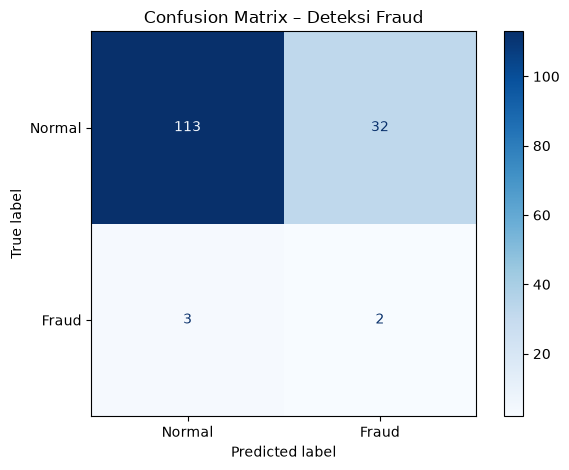

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Membuat visualisasi confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Normal', 'Fraud']
).plot(
    cmap='Blues',
    values_format='d'
)

# Memberikan judul grafik
plt.title('Confusion Matrix – Deteksi Fraud')

# Mengatur tata letak
plt.tight_layout()

# Menampilkan grafik
plt.show()


## 4.6 Interpretasi dan Studi Kasus

Pada tahap ini, dilakukan interpretasi terhadap hasil evaluasi model klasifikasi dalam konteks deteksi transaksi fraud pada pembayaran digital.

Dalam sistem deteksi fraud, terdapat dua jenis kesalahan prediksi yang memiliki konsekuensi berbeda.

Pertama, False Negative (FN), yaitu transaksi fraud yang tidak berhasil dideteksi oleh model. Kesalahan ini dapat menyebabkan kerugian finansial karena transaksi penipuan dianggap sebagai transaksi normal.

Kedua, False Positive (FP), yaitu transaksi normal yang salah dikategorikan sebagai fraud. Kesalahan ini dapat mengganggu pelanggan karena transaksi yang sebenarnya sah justru mendapatkan peringatan atau pembatasan.

Recall yang tinggi dapat membantu mengurangi jumlah transaksi fraud yang terlewat, sedangkan precision yang tinggi menunjukkan bahwa alarm fraud yang diberikan model lebih tepat.

Namun, peningkatan recall dapat menyebabkan peningkatan alarm palsu. Oleh karena itu, pemilihan metrik evaluasi harus mempertimbangkan konsekuensi dan biaya dari masing-masing kesalahan prediksi.


### Analisis Hasil Confusion Matrix

Berdasarkan hasil pengujian model Decision Tree, diperoleh nilai
True Positive (TP) sebesar 2, True Negative (TN) sebesar 113,
False Positive (FP) sebesar 32, dan False Negative (FN) sebesar 3.

Hasil tersebut menunjukkan bahwa model berhasil mengklasifikasikan
113 transaksi normal dengan benar dan mendeteksi 2 transaksi fraud
dengan benar. Namun, masih terdapat 32 transaksi normal yang salah
dikategorikan sebagai fraud serta 3 transaksi fraud yang tidak
berhasil terdeteksi.

Dalam konteks deteksi fraud, kesalahan prediksi tersebut memiliki
konsekuensi sebagai berikut:

1. **False Positive (FP) sebanyak 32 transaksi**

   Sebanyak 32 transaksi yang sebenarnya normal justru dikategorikan
   sebagai fraud oleh model. Kondisi ini dapat menyebabkan pelanggan
   mengalami gangguan, seperti transaksi tertunda atau mendapatkan
   pemeriksaan tambahan meskipun transaksinya sah.

2. **False Negative (FN) sebanyak 3 transaksi**

   Sebanyak 3 transaksi yang sebenarnya fraud justru dikategorikan
   sebagai transaksi normal. Kondisi ini berpotensi menimbulkan
   kerugian finansial karena transaksi penipuan tidak berhasil
   terdeteksi oleh sistem.

Berdasarkan hasil tersebut, model memiliki kemampuan yang lebih
baik dalam mengenali transaksi normal dibandingkan mendeteksi
transaksi fraud. Hal ini terlihat dari jumlah True Negative yang
mencapai 113, sedangkan True Positive hanya sebanyak 2 transaksi.

Oleh karena itu, evaluasi model deteksi fraud tidak cukup hanya
memperhatikan jumlah prediksi yang benar. Model juga perlu
memperhatikan kemampuan mendeteksi transaksi fraud agar risiko
kerugian finansial dapat diminimalkan.

### Kesimpulan Interpretasi

Hasil pengujian menunjukkan bahwa model Decision Tree masih
memiliki kelemahan dalam mendeteksi transaksi fraud. Meskipun
sebagian besar transaksi normal berhasil dikenali, masih terdapat
transaksi fraud yang tidak terdeteksi dan cukup banyak transaksi
normal yang mendapatkan prediksi fraud.

Dengan demikian, diperlukan evaluasi lebih lanjut menggunakan
precision, recall, F1-Score, serta pengujian threshold untuk
mengetahui bagaimana performa model dapat disesuaikan dengan
kebutuhan deteksi fraud.


## 4.7 Eksperimen: Baseline Semua Normal

Pada tahap ini, dilakukan eksperimen dengan membuat model baseline yang selalu memprediksi seluruh transaksi sebagai transaksi normal (kelas 0), tanpa memperhatikan karakteristik transaksi.

Model baseline digunakan sebagai pembanding terhadap model Decision Tree yang telah dilatih sebelumnya.

Tujuan eksperimen ini adalah memahami bahwa nilai accuracy yang tinggi belum tentu menunjukkan bahwa sebuah model memiliki kemampuan klasifikasi yang baik, terutama ketika dataset memiliki distribusi kelas yang tidak seimbang.

Pada kasus deteksi fraud, apabila jumlah transaksi normal jauh lebih banyak dibandingkan transaksi fraud, model yang selalu memprediksi normal masih dapat memperoleh accuracy yang tinggi. Namun, model tersebut tidak mampu mendeteksi transaksi fraud sehingga recall untuk kelas fraud bernilai nol.

Hasil baseline kemudian dibandingkan dengan hasil klasifikasi Decision Tree menggunakan `classification_report()`.

In [11]:
import numpy as np

from sklearn.metrics import (
    classification_report,
    accuracy_score
)

# Membuat prediksi baseline:
# Seluruh transaksi diprediksi sebagai normal (0)
baseline = np.zeros(len(y_test), dtype=int)

# Menghitung accuracy baseline
print("Baseline Accuracy:")
print(accuracy_score(y_test, baseline))

# Menampilkan classification report baseline
print("\nClassification Report Baseline:")
print(
    classification_report(
        y_test,
        baseline,
        labels=[0, 1],
        zero_division=0
    )
)

# Menampilkan hasil Decision Tree
print("\nClassification Report Decision Tree:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        zero_division=0
    )
)


Baseline Accuracy:
0.9666666666666667

Classification Report Baseline:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       145
           1       0.00      0.00      0.00         5

    accuracy                           0.97       150
   macro avg       0.48      0.50      0.49       150
weighted avg       0.93      0.97      0.95       150


Classification Report Decision Tree:
              precision    recall  f1-score   support

           0       0.97      0.78      0.87       145
           1       0.06      0.40      0.10         5

    accuracy                           0.77       150
   macro avg       0.52      0.59      0.48       150
weighted avg       0.94      0.77      0.84       150



## 4.8 Eksperimen: Pengaruh Ambang Prediksi (Threshold)

Pada tahap ini, dilakukan eksperimen untuk mengetahui pengaruh perubahan nilai ambang prediksi (threshold) terhadap hasil klasifikasi transaksi fraud.

Model Decision Tree menghasilkan probabilitas untuk setiap kelas melalui fungsi `predict_proba()`. Probabilitas tersebut digunakan untuk menentukan apakah suatu transaksi akan dikategorikan sebagai fraud atau normal.

Pada eksperimen ini, digunakan empat nilai threshold, yaitu 0.2, 0.4, 0.5, dan 0.7.

Ketentuan klasifikasi yang digunakan adalah:

- Jika probabilitas fraud lebih besar atau sama dengan threshold, transaksi dikategorikan sebagai fraud (1).
- Jika probabilitas fraud lebih kecil dari threshold, transaksi dikategorikan sebagai normal (0).

Selanjutnya, setiap nilai threshold dievaluasi menggunakan precision dan recall.

Tujuan eksperimen ini adalah memahami hubungan antara perubahan threshold dengan kemampuan model dalam mendeteksi transaksi fraud serta ketepatan prediksi fraud.

In [12]:
from sklearn.metrics import precision_score, recall_score

# Mengambil probabilitas prediksi kelas fraud (1)
y_prob = model.predict_proba(X_test)[
    :, list(model.classes_).index(1)
]

# Menguji empat nilai threshold
for threshold in [0.2, 0.4, 0.5, 0.7]:

    # Mengubah probabilitas menjadi prediksi kelas
    pred = (y_prob >= threshold).astype(int)

    # Menghitung precision
    precision = precision_score(
        y_test,
        pred,
        zero_division=0
    )

    # Menghitung recall
    recall = recall_score(
        y_test,
        pred,
        zero_division=0
    )

    # Menampilkan hasil
    print(
        threshold,
        'precision=', round(precision, 3),
        'recall=', round(recall, 3)
    )


0.2 precision= 0.059 recall= 0.4
0.4 precision= 0.059 recall= 0.4
0.5 precision= 0.059 recall= 0.4
0.7 precision= 0.056 recall= 0.2



### Analisis Hasil Eksperimen Threshold

Berdasarkan eksperimen yang telah dilakukan, diperoleh hasil
pengujian menggunakan empat nilai threshold, yaitu 0.2, 0.4,
0.5, dan 0.7.

Hasil pengujian menunjukkan bahwa:

1. **Threshold 0.2**

   Menghasilkan precision sebesar 0.059 dan recall sebesar 0.400.
   Artinya, model mampu mendeteksi 40% dari seluruh transaksi
   fraud yang sebenarnya.

2. **Threshold 0.4**

   Menghasilkan precision sebesar 0.059 dan recall sebesar 0.400.
   Hasil ini menunjukkan bahwa performa model tidak mengalami
   perubahan dibandingkan threshold 0.2.

3. **Threshold 0.5**

   Menghasilkan precision sebesar 0.059 dan recall sebesar 0.400.
   Nilai precision dan recall masih sama dengan dua pengujian
   sebelumnya.

4. **Threshold 0.7**

   Menghasilkan precision sebesar 0.056 dan recall sebesar 0.200.
   Hal ini menunjukkan adanya penurunan kemampuan model dalam
   mendeteksi transaksi fraud dibandingkan threshold sebelumnya.

### Analisis Pengaruh Perubahan Threshold

Berdasarkan hasil eksperimen, perubahan threshold tidak selalu
menghasilkan perubahan performa model secara langsung.

Pada threshold 0.2, 0.4, dan 0.5, nilai precision dan recall
tetap sama. Hal ini menunjukkan bahwa perubahan ambang pada
rentang tersebut belum mengubah hasil klasifikasi transaksi.

Sementara itu, ketika threshold dinaikkan menjadi 0.7,
nilai recall mengalami penurunan dari 0.400 menjadi 0.200.
Artinya, kemampuan model dalam menemukan transaksi fraud
menjadi lebih rendah.

Penurunan recall tersebut menunjukkan bahwa semakin tinggi
threshold yang digunakan, semakin banyak transaksi yang harus
memiliki probabilitas fraud tinggi agar dikategorikan sebagai
transaksi fraud.

### Kesimpulan Eksperimen

Berdasarkan hasil pengujian, threshold 0.2, 0.4, dan 0.5
memberikan hasil evaluasi yang sama, yaitu precision sebesar
0.059 dan recall sebesar 0.400. Sementara itu, threshold 0.7
menghasilkan recall yang lebih rendah, yaitu 0.200.

Dengan demikian, untuk kasus deteksi fraud yang lebih
memprioritaskan pencegahan transaksi penipuan, threshold 0.2,
0.4, atau 0.5 lebih sesuai dibandingkan threshold 0.7
berdasarkan hasil eksperimen ini.

Namun, nilai precision yang masih rendah menunjukkan bahwa
model juga menghasilkan banyak alarm fraud palsu. Oleh karena
itu, pemilihan threshold tetap perlu mempertimbangkan
keseimbangan antara kemampuan mendeteksi fraud dan jumlah
transaksi normal yang salah ditandai sebagai fraud.



# 5. TUGAS PRAKTIKUM

Pada bagian ini, dilakukan pengerjaan tugas praktikum untuk
memperdalam pemahaman mengenai evaluasi model klasifikasi
menggunakan Confusion Matrix, Accuracy, Precision, Recall,
dan F1-Score.

Pengerjaan tugas mengacu pada hasil praktikum yang telah
dilakukan sebelumnya, mulai dari proses pembangkitan dataset,
pelatihan model Decision Tree, perhitungan metrik evaluasi,
hingga eksperimen pengaruh threshold.

Tugas praktikum terdiri dari empat bagian, yaitu perhitungan
manual, verifikasi menggunakan Python, evaluasi pada data
tidak seimbang, serta eksperimen dan rekomendasi threshold.



## 5.1 Tugas 1 — Hitung Manual

Pada tugas pertama, dilakukan perhitungan metrik evaluasi
klasifikasi secara manual berdasarkan nilai True Positive (TP),
True Negative (TN), False Positive (FP), dan False Negative (FN)
yang telah diberikan dalam soal.

Diketahui hasil klasifikasi sebagai berikut:

- True Positive (TP) = 24
- True Negative (TN) = 156
- False Positive (FP) = 12
- False Negative (FN) = 8

Berdasarkan nilai tersebut, akan disusun Confusion Matrix
dan dilakukan perhitungan empat metrik evaluasi, yaitu
Accuracy, Precision, Recall, dan F1-Score.

Perhitungan dilakukan menggunakan rumus evaluasi klasifikasi
untuk mengetahui tingkat ketepatan model dalam mengenali
transaksi normal maupun transaksi fraud.



### Perhitungan Matematis

**1. Accuracy**

Accuracy = (TP + TN) / (TP + TN + FP + FN)

= (24 + 156) / (24 + 156 + 12 + 8)

= 180 / 200

= 0.90 = 90%

**2. Precision**

Precision = TP / (TP + FP)

= 24 / (24 + 12)

= 24 / 36

= 0.6667 = 66.67%

**3. Recall**

Recall = TP / (TP + FN)

= 24 / (24 + 8)

= 24 / 32

= 0.75 = 75%

**4. F1-Score**

F1 = 2 × (Precision × Recall) / (Precision + Recall)

= 2 × (0.6667 × 0.75) / (0.6667 + 0.75)

= 0.7059 = 70.59%


In [14]:
# Nilai confusion matrix berdasarkan soal
TP = 24
TN = 156
FP = 12
FN = 8

# Menyusun confusion matrix
cm_manual = np.array([
    [TN, FP],
    [FN, TP]
])

print("Confusion Matrix:")
print(cm_manual)

# Menghitung Accuracy
accuracy_manual = (TP + TN) / (TP + TN + FP + FN)

# Menghitung Precision
precision_manual = TP / (TP + FP)

# Menghitung Recall
recall_manual = TP / (TP + FN)

# Menghitung F1-Score
f1_manual = (
    2 * precision_manual * recall_manual
    / (precision_manual + recall_manual)
)

# Menampilkan hasil perhitungan
print("\nHasil Perhitungan Manual:")
print(f"Accuracy  = {accuracy_manual:.4f} ({accuracy_manual*100:.2f}%)")
print(f"Precision = {precision_manual:.4f} ({precision_manual*100:.2f}%)")
print(f"Recall    = {recall_manual:.4f} ({recall_manual*100:.2f}%)")
print(f"F1-Score  = {f1_manual:.4f} ({f1_manual*100:.2f}%)")


Confusion Matrix:
[[156  12]
 [  8  24]]

Hasil Perhitungan Manual:
Accuracy  = 0.9000 (90.00%)
Precision = 0.6667 (66.67%)
Recall    = 0.7500 (75.00%)
F1-Score  = 0.7059 (70.59%)



### Analisis dan Interpretasi Hasil Tugas 1

Berdasarkan hasil perhitungan manual, diperoleh nilai Accuracy
sebesar 90%, Precision sebesar 66,67%, Recall sebesar 75%,
dan F1-Score sebesar 70,59%.

Nilai Accuracy sebesar 90% menunjukkan bahwa model berhasil
mengklasifikasikan 180 dari 200 transaksi dengan benar.

Nilai Precision sebesar 66,67% menunjukkan bahwa dari seluruh
transaksi yang diprediksi sebagai fraud, sekitar 66,67%
merupakan transaksi yang benar-benar fraud.

Nilai Recall sebesar 75% menunjukkan bahwa model berhasil
mendeteksi 75% dari seluruh transaksi fraud yang sebenarnya.

Sementara itu, F1-Score sebesar 70,59% menunjukkan tingkat
keseimbangan antara Precision dan Recall.

Dalam konteks deteksi fraud, terdapat dua kesalahan klasifikasi
yang perlu diperhatikan:

1. **False Positive (FP) sebanyak 12 transaksi**

   Terdapat 12 transaksi normal yang salah dikategorikan
   sebagai fraud. Kondisi ini dapat menyebabkan transaksi
   pelanggan yang sebenarnya sah mendapatkan pemeriksaan
   tambahan atau bahkan tertunda.

2. **False Negative (FN) sebanyak 8 transaksi**

   Terdapat 8 transaksi fraud yang salah dikategorikan sebagai
   transaksi normal. Kondisi ini dapat menyebabkan transaksi
   penipuan tidak terdeteksi sehingga berpotensi menimbulkan
   kerugian finansial.

### Kesimpulan Tugas 1

Berdasarkan perhitungan tersebut, model memperoleh Accuracy
sebesar 90%, tetapi masih terdapat kesalahan klasifikasi
berupa 12 False Positive dan 8 False Negative.

Oleh karena itu, evaluasi model klasifikasi tidak cukup hanya
menggunakan Accuracy, tetapi juga perlu mempertimbangkan
Precision, Recall, dan F1-Score agar kemampuan model dalam
mendeteksi transaksi fraud dapat dinilai secara lebih menyeluruh.



## 5.2 Tugas 2 — Verifikasi Python

Pada tugas kedua, dilakukan verifikasi hasil evaluasi model
klasifikasi menggunakan Python dan library scikit-learn.

Verifikasi ini menggunakan dataset sintetis transaksi
pembayaran digital yang telah dibuat pada Bagian 4.1
dan model Decision Tree yang telah dilatih pada Bagian 4.2.

Proses verifikasi meliputi penampilan dataset awal,
perhitungan Confusion Matrix, identifikasi nilai TP, TN,
FP, dan FN, serta perhitungan metrik Accuracy, Precision,
Recall, dan F1-Score.

Selanjutnya, hasil perhitungan manual dibandingkan dengan
hasil perhitungan menggunakan fungsi evaluasi scikit-learn.

Tujuan dari tugas ini adalah memastikan bahwa hasil
perhitungan manual sesuai dengan hasil yang diperoleh
melalui library scikit-learn.


In [15]:
# Menampilkan lima data transaksi pertama
print("Lima Data Transaksi Pertama:")
display(df.head())

# Menampilkan distribusi kelas
print("\nDistribusi Kelas:")
print(df['isFraud'].value_counts())

# Menampilkan jumlah keseluruhan data
print("\nJumlah Data:", len(df))


Lima Data Transaksi Pertama:


,amount,hour,new_device,foreign_ip,isFraud
0,201.28,9,0,0,0
1,52.46,8,0,0,0
2,314.33,17,1,0,0
3,380.15,3,0,0,0
4,21.09,5,1,0,0



Distribusi Kelas:
isFraud
0    484
1     16
Name: count, dtype: int64

Jumlah Data: 500


In [16]:
# Menghitung ulang confusion matrix
cm_verifikasi = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

# Mengambil nilai TN, FP, FN, dan TP
tn_v, fp_v, fn_v, tp_v = cm_verifikasi.ravel()

print("Confusion Matrix:")
print(cm_verifikasi)

print("\nKomponen Confusion Matrix:")
print("True Negative (TN) :", tn_v)
print("False Positive (FP):", fp_v)
print("False Negative (FN):", fn_v)
print("True Positive (TP) :", tp_v)


Confusion Matrix:
[[113  32]
 [  3   2]]

Komponen Confusion Matrix:
True Negative (TN) : 113
False Positive (FP): 32
False Negative (FN): 3
True Positive (TP) : 2


In [17]:
# Menghitung metrik secara manual
accuracy_v = (tp_v + tn_v) / (tp_v + tn_v + fp_v + fn_v)

precision_v = tp_v / (tp_v + fp_v) if (tp_v + fp_v) else 0

recall_v = tp_v / (tp_v + fn_v) if (tp_v + fn_v) else 0

f1_v = (
    2 * precision_v * recall_v / (precision_v + recall_v)
    if (precision_v + recall_v) else 0
)

# Menghitung menggunakan scikit-learn
accuracy_sk = accuracy_score(y_test, y_pred)

precision_sk = precision_score(
    y_test, y_pred, zero_division=0
)

recall_sk = recall_score(
    y_test, y_pred, zero_division=0
)

f1_sk = f1_score(
    y_test, y_pred, zero_division=0
)

# Membandingkan kedua hasil
hasil_verifikasi = pd.DataFrame({
    'Metrik': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Perhitungan Manual': [
        accuracy_v, precision_v, recall_v, f1_v
    ],
    'Scikit-Learn': [
        accuracy_sk, precision_sk, recall_sk, f1_sk
    ]
})

print("Perbandingan Hasil Evaluasi:")
display(hasil_verifikasi.round(3))

# Memastikan kedua hasil sama
assert np.allclose(
    [accuracy_v, precision_v, recall_v, f1_v],
    [accuracy_sk, precision_sk, recall_sk, f1_sk]
)

print("Verifikasi berhasil: hasil perhitungan manual dan scikit-learn sama.")


Perbandingan Hasil Evaluasi:


,Metrik,Perhitungan Manual,Scikit-Learn
0,Accuracy,0.767,0.767
1,Precision,0.059,0.059
2,Recall,0.400,0.400
3,F1-Score,0.103,0.103


Verifikasi berhasil: hasil perhitungan manual dan scikit-learn sama.



### Analisis dan Interpretasi Hasil Tugas 2

Berdasarkan hasil verifikasi menggunakan Python, diperoleh
Confusion Matrix dengan nilai True Negative (TN) sebanyak
113, False Positive (FP) sebanyak 32, False Negative (FN)
sebanyak 3, dan True Positive (TP) sebanyak 2.

Hasil evaluasi model Decision Tree menunjukkan nilai
Accuracy sebesar 0.767, Precision sebesar 0.059,
Recall sebesar 0.400, dan F1-Score sebesar 0.103.

Setelah dilakukan perbandingan antara perhitungan manual
dan fungsi evaluasi scikit-learn, diperoleh hasil yang sama
pada keempat metrik evaluasi.

Hal ini menunjukkan bahwa proses perhitungan manual telah
dilakukan dengan benar dan sesuai dengan hasil yang
dihasilkan oleh library scikit-learn.

Meskipun demikian, hasil evaluasi menunjukkan bahwa model
masih memiliki kemampuan yang rendah dalam memberikan
prediksi fraud secara tepat. Hal tersebut terlihat dari
nilai Precision sebesar 0.059 dan F1-Score sebesar 0.103.

### Kesimpulan Tugas 2

Berdasarkan proses verifikasi, dapat disimpulkan bahwa
perhitungan manual dan perhitungan menggunakan scikit-learn
menghasilkan nilai yang konsisten.

Dengan demikian, Confusion Matrix dan metrik evaluasi yang
dihasilkan oleh model Decision Tree telah berhasil diverifikasi.



## 5.3 Tugas 3 — Evaluasi Data Tidak Seimbang

Pada tugas ketiga, dilakukan evaluasi terhadap model klasifikasi
pada dataset yang memiliki distribusi kelas tidak seimbang
(class imbalance).

Evaluasi dilakukan dengan membandingkan model baseline yang
selalu memprediksi transaksi sebagai normal dengan model
Decision Tree yang telah dilatih sebelumnya.

Perbandingan menggunakan hasil eksperimen pada Bagian 4.7,
yaitu berdasarkan nilai Accuracy, Precision, Recall,
dan F1-Score.

Tujuan dari tugas ini adalah mengetahui kelemahan penggunaan
Accuracy sebagai satu-satunya metrik evaluasi, khususnya
ketika jumlah data pada kelas normal jauh lebih banyak
dibandingkan jumlah data pada kelas fraud.


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Membuat prediksi baseline semua normal
baseline = np.zeros(len(y_test), dtype=int)

# Membuat fungsi untuk menghitung metrik
def evaluasi_model(y_true, y_prediction, nama_model):

    return {
        'Model': nama_model,
        'Accuracy': accuracy_score(y_true, y_prediction),
        'Precision Fraud': precision_score(
            y_true, y_prediction, zero_division=0
        ),
        'Recall Fraud': recall_score(
            y_true, y_prediction, zero_division=0
        ),
        'F1-Score Fraud': f1_score(
            y_true, y_prediction, zero_division=0
        )
    }

# Mengevaluasi kedua model
hasil_baseline = evaluasi_model(
    y_test, baseline, 'Baseline'
)

hasil_decision_tree = evaluasi_model(
    y_test, y_pred, 'Decision Tree'
)

# Membuat tabel perbandingan
perbandingan = pd.DataFrame([
    hasil_baseline,
    hasil_decision_tree
])

print("Perbandingan Baseline dan Decision Tree:")
display(perbandingan.round(3))


Perbandingan Baseline dan Decision Tree:


,Model,Accuracy,Precision Fraud,Recall Fraud,F1-Score Fraud
0,Baseline,0.967,0.000,0.0,0.000
1,Decision Tree,0.767,0.059,0.4,0.103



### Analisis Perbandingan Baseline dan Decision Tree

Berdasarkan hasil eksperimen, model baseline memperoleh
Accuracy sebesar 0.967 atau 96,67%, sedangkan model
Decision Tree memperoleh Accuracy sebesar 0.767 atau 76,67%.

Jika hanya dilihat dari nilai Accuracy, model baseline
terlihat memiliki performa yang lebih baik dibandingkan
Decision Tree.

Namun, ketika dilihat dari kemampuan mendeteksi transaksi
fraud, hasilnya berbeda.

Model baseline memiliki Recall fraud sebesar 0.000.
Hal ini terjadi karena seluruh transaksi diprediksi sebagai
normal sehingga tidak ada transaksi fraud yang berhasil
terdeteksi.

Sementara itu, model Decision Tree memperoleh Recall fraud
sebesar 0.400. Artinya, model berhasil mendeteksi 40% dari
seluruh transaksi fraud yang terdapat pada data uji.

Berdasarkan classification report, terdapat 145 transaksi
normal dan hanya 5 transaksi fraud pada data uji.
Kondisi tersebut menunjukkan bahwa distribusi kelas
pada data uji tidak seimbang.

Model baseline dapat memperoleh Accuracy tinggi karena
sebagian besar data merupakan transaksi normal. Akan tetapi,
model tersebut tidak memiliki kemampuan untuk mendeteksi
transaksi fraud.

Sebaliknya, Decision Tree memiliki Accuracy lebih rendah,
tetapi mampu mendeteksi sebagian transaksi fraud.

### Mengapa Accuracy Tinggi Belum Tentu Menunjukkan
### Kemampuan Deteksi Fraud yang Baik?

Accuracy hanya menghitung perbandingan seluruh prediksi
yang benar terhadap jumlah keseluruhan data. Metrik ini
tidak secara langsung menunjukkan kemampuan model dalam
mengenali kelas minoritas.

Pada kasus ini, terdapat 145 transaksi normal dan hanya
5 transaksi fraud pada data uji. Oleh karena itu, model
yang selalu memprediksi normal dapat memperoleh Accuracy
sebesar 96,67%, meskipun tidak berhasil mendeteksi satu pun
transaksi fraud.

Untuk mengatasi permasalahan tersebut, evaluasi model
perlu memperhatikan Precision, Recall, dan F1-Score,
khususnya pada kelas fraud.

### Kesimpulan Tugas 3

Berdasarkan hasil perbandingan, Accuracy tidak dapat
digunakan sebagai satu-satunya indikator untuk menilai
kualitas model klasifikasi pada data tidak seimbang.

Model baseline memiliki Accuracy lebih tinggi, tetapi
Recall fraud sebesar 0.000. Sementara itu, Decision Tree
memiliki Recall fraud sebesar 0.400 sehingga lebih mampu
mendeteksi transaksi fraud.

Dengan demikian, pada kasus deteksi fraud, Recall dan
F1-Score perlu diperhatikan selain Accuracy karena
kemampuan menemukan transaksi fraud merupakan salah satu
tujuan utama sistem klasifikasi.



## 5.4 Tugas 4 — Eksperimen dan Rekomendasi

Pada tugas keempat, dilakukan eksperimen untuk mengetahui
pengaruh perubahan nilai threshold terhadap hasil klasifikasi
transaksi fraud.

Pengujian menggunakan model Decision Tree yang telah dilatih
pada tahap sebelumnya dengan empat nilai threshold, yaitu
0.2, 0.4, 0.5, dan 0.7.

Setiap nilai threshold dievaluasi menggunakan metrik
Precision dan Recall untuk mengetahui ketepatan prediksi
fraud serta kemampuan model dalam mendeteksi transaksi fraud.

Selanjutnya, dilakukan pemilihan threshold yang sesuai
untuk skenario ketika biaya False Negative (FN) lebih tinggi
dibandingkan False Positive (FP).

Tujuan dari eksperimen ini adalah menentukan ambang prediksi
yang sesuai dengan kebutuhan deteksi fraud berdasarkan
hasil pengujian dan konsekuensi kesalahan klasifikasi.


In [20]:
from sklearn.metrics import precision_score, recall_score

# Mengambil probabilitas prediksi kelas fraud
y_prob = model.predict_proba(X_test)[
    :, list(model.classes_).index(1)
]

# Menentukan nilai threshold yang diuji
thresholds = [0.2, 0.4, 0.5, 0.7]

# Menyimpan hasil pengujian
hasil_threshold = []

for threshold in thresholds:

    # Mengubah probabilitas menjadi prediksi kelas
    pred = (y_prob >= threshold).astype(int)

    # Menghitung precision
    precision = precision_score(
        y_test, pred, zero_division=0
    )

    # Menghitung recall
    recall = recall_score(
        y_test, pred, zero_division=0
    )

    # Menyimpan hasil
    hasil_threshold.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall
    })

# Membuat tabel hasil eksperimen
tabel_threshold = pd.DataFrame(hasil_threshold)

print("Tabel Hasil Eksperimen Threshold:")
display(tabel_threshold.round(3))


Tabel Hasil Eksperimen Threshold:


,Threshold,Precision,Recall
0,0.2,0.059,0.4
1,0.4,0.059,0.4
2,0.5,0.059,0.4
3,0.7,0.056,0.2



### Analisis Pengaruh Threshold terhadap Precision dan Recall

Berdasarkan hasil eksperimen, diperoleh nilai Precision
dan Recall yang berbeda pada beberapa pengujian threshold.

Pada threshold 0.2, 0.4, dan 0.5, model menghasilkan
Precision sebesar 0.059 dan Recall sebesar 0.400.
Hal ini menunjukkan bahwa ketiga nilai threshold tersebut
memberikan hasil evaluasi yang sama.

Sementara itu, pada threshold 0.7, Precision mengalami
penurunan menjadi 0.056 dan Recall menjadi 0.200.

Hasil tersebut menunjukkan bahwa pada threshold 0.7,
kemampuan model dalam mendeteksi transaksi fraud mengalami
penurunan dibandingkan tiga threshold sebelumnya.

Perubahan threshold dapat memengaruhi jumlah transaksi
yang dikategorikan sebagai fraud. Threshold yang lebih
rendah memungkinkan lebih banyak transaksi dikategorikan
sebagai fraud, sedangkan threshold yang lebih tinggi
membutuhkan probabilitas yang lebih besar agar transaksi
dapat dikategorikan sebagai fraud.

Namun, berdasarkan hasil eksperimen ini, perubahan
threshold dari 0.2 menjadi 0.4 dan 0.5 belum menghasilkan
perubahan nilai Precision maupun Recall.

### Rekomendasi Pemilihan Threshold

Dalam sistem deteksi fraud, biaya False Negative (FN)
lebih tinggi dibandingkan False Positive (FP).

Hal tersebut berarti transaksi fraud yang tidak berhasil
terdeteksi dapat menimbulkan kerugian finansial yang lebih
besar dibandingkan transaksi normal yang salah ditandai
sebagai fraud.

Oleh karena itu, sistem perlu memprioritaskan kemampuan
mendeteksi transaksi fraud dengan mempertimbangkan nilai
Recall.

Berdasarkan hasil eksperimen, threshold 0.2, 0.4, dan 0.5
memiliki hasil evaluasi yang sama, yaitu Precision sebesar
0.059 dan Recall sebesar 0.400.

Dari ketiga nilai tersebut, threshold 0.2 dapat dipilih
sebagai rekomendasi karena merupakan ambang terendah
yang diuji dan sesuai dengan kebijakan deteksi yang lebih
sensitif terhadap transaksi fraud.

Meskipun demikian, threshold 0.2 tidak terbukti menghasilkan
Recall yang lebih tinggi dibandingkan threshold 0.4 dan 0.5
pada eksperimen ini. Ketiganya memberikan hasil yang sama.

Threshold 0.7 tidak direkomendasikan untuk skenario ini
karena menghasilkan Recall lebih rendah, yaitu 0.200,
sehingga lebih banyak transaksi fraud berpotensi terlewat.

### Kesimpulan Tugas 4

Berdasarkan eksperimen yang telah dilakukan, threshold
0.2, 0.4, dan 0.5 menghasilkan nilai Precision dan Recall
yang sama. Sementara itu, threshold 0.7 menghasilkan
penurunan Recall.

Dengan mempertimbangkan bahwa biaya False Negative lebih
tinggi daripada False Positive, threshold 0.2 dipilih
sebagai rekomendasi berdasarkan hasil pengujian ini.

Pemilihan tersebut bertujuan memprioritaskan deteksi fraud,
meskipun model masih menghasilkan Precision yang rendah.
Oleh karena itu, diperlukan pengembangan dan evaluasi
lebih lanjut agar kemampuan model dalam mendeteksi fraud
dapat ditingkatkan tanpa menghasilkan terlalu banyak
alarm palsu.


## 6. Kesimpulan Praktikum

Berdasarkan praktikum evaluasi model klasifikasi yang telah dilakukan, dapat disimpulkan bahwa evaluasi model klasifikasi tidak cukup hanya menggunakan nilai accuracy, tetapi juga perlu memperhatikan precision, recall, dan F1-score. Keempat metrik tersebut memberikan gambaran yang lebih menyeluruh mengenai kemampuan model dalam melakukan klasifikasi.

Pada praktikum ini, digunakan dataset sintetis transaksi pembayaran digital dengan label `isFraud` untuk membedakan transaksi normal dan transaksi fraud. Model klasifikasi yang diterapkan adalah Decision Tree Classifier dengan pembagian data latih dan data uji sebesar 70:30.

Hasil pengujian menunjukkan bahwa model memperoleh accuracy sebesar 76,7%, precision sebesar 5,9%, recall sebesar 40%, dan F1-score sebesar 10,3%. Hasil confusion matrix menunjukkan bahwa model berhasil mendeteksi sebagian transaksi fraud, tetapi masih menghasilkan banyak kesalahan prediksi, khususnya transaksi normal yang salah diklasifikasikan sebagai fraud.

Melalui eksperimen baseline, diketahui bahwa model yang selalu memprediksi transaksi sebagai normal dapat memperoleh accuracy sebesar 96,7%, tetapi tidak mampu mendeteksi transaksi fraud. Hal ini membuktikan bahwa accuracy yang tinggi belum tentu menunjukkan bahwa model memiliki kemampuan klasifikasi yang baik, terutama ketika dataset memiliki distribusi kelas yang tidak seimbang.

Selain itu, eksperimen perubahan threshold menunjukkan bahwa nilai threshold memengaruhi hasil precision dan recall. Pada pengujian ini, threshold 0,2, 0,4, dan 0,5 menghasilkan precision dan recall yang sama, sedangkan threshold 0,7 menghasilkan recall yang lebih rendah. Oleh karena itu, pemilihan threshold perlu mempertimbangkan konsekuensi kesalahan klasifikasi, terutama apabila transaksi fraud yang tidak terdeteksi (False Negative) memiliki biaya lebih besar.

Secara keseluruhan, praktikum ini memberikan pemahaman mengenai penggunaan confusion matrix, perhitungan metrik evaluasi secara manual dan menggunakan scikit-learn, serta pentingnya mempertimbangkan ketidakseimbangan kelas dalam evaluasi model klasifikasi. Model yang dihasilkan masih dapat dikembangkan lebih lanjut agar mampu meningkatkan kemampuan mendeteksi transaksi fraud sekaligus mengurangi kesalahan prediksi.